In [55]:
## Standard libraries

## Imports for plotting
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

## PyTorch
import torch

## Torchvision
import torchvision
import torchvision.transforms as T

## Sklearn
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST, SVHN, USPS
from umap import UMAP

# ## UMAP
# try:
#     IN_COLAB = True
# except:
#     IN_COLAB = False

# if IN_COLAB:
#     print("Using Google Colab")
#     !pip install umap-learn
#     from umap import UMAP
# else:
#     from umap import UMAP
# # Path to the folder where the datasets are/should be downloaded
DATASET_PATH = "./data"

In [56]:
print("Using torch", torch.__version__)

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS (MacBook) device found.")
    # print('Number of MPS cards: ', torch.mps.device_count())
    # print('Total MPS memory {0:.2f} GB'.format(torch.mps.recommended_max_memory()/pow(10,9)))
elif torch.backends.cuda.is_built() and torch.cuda.is_available():
    device = torch.device("cuda")
    # Ensure that all operations are deterministic on GPU (if used) for reproducibility
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print("CUDA device found.")
    print(
        "Number of GPU cards: ",
        torch.cuda.device_count(),
        "\nWhich card GPU?",
        torch.cuda.get_device_name(0),
    )
    print(
        f"Total GPU memory {torch.cuda.mem_get_info()[1] / pow(10, 9):.2f} GB. Free GPU memory {torch.cuda.mem_get_info()[0] / pow(10, 9):.2f} GB",
    )
else:
    device = torch.device("cpu")
    print("No MPS or CUDA has been found. PyTorch will use CPU.")

Using torch 2.8.0+cu128
No MPS or CUDA has been found. PyTorch will use CPU.


In this practical session you will implement and test the method presented in [1] for Unsupervised Domain Adaptation.

You will use three imaging datasets showing 0-9 digits: MNIST, SVHN and USPS.

We know that the output spaces are equal (same labels/classes), namely the digits from 0 to 9, and we will resize the data so that the input spaces are also equal (same number of pixels per image).

In this TP, you will assume a covariate shift and therefore that there is a shift between the marginal disitributions $p_S(X)$ and $p_T(X)$ and that the conditionl distributions $p_S(Y|X)$ and $p_t(Y|X)$ are equal.

As for the other TP, answer all questions and fill the code where you see **XXXXXXXXX**

**Deadline**: please verify on the Moodle/Ecampus the deadline



[1] B. Fernando et al. “Unsupervised Visual Domain Adaptation Using Subspace Alignment”. In: ICCV. 2013.

### **MNIST**

 Let's start by downloading the **MNIST** dataset: a very common and large database of grayscale images showing handwritten digits ranging from 0 to 9. It comprises 60,000 training images and 10,000 testing images of size 28x28.

To cope with the assumption about the "same number of input pixels per image", we choose the input dimension of 32x32 for all datasets. We thus resize all images (originally 28x28) using the padding function "Pad" (add 0 to the borders).


In [57]:
# Transform to normalized Tensors in the range [0,1]
MNIST_train_dataset = MNIST(
    root=DATASET_PATH,
    train=True,
    download=True,
    transform=T.Compose([T.Pad(2), T.ToTensor()]),
)
MNIST_test_dataset = MNIST(
    root=DATASET_PATH,
    train=False,
    download=True,
    transform=T.Compose([T.Pad(2), T.ToTensor()]),
)

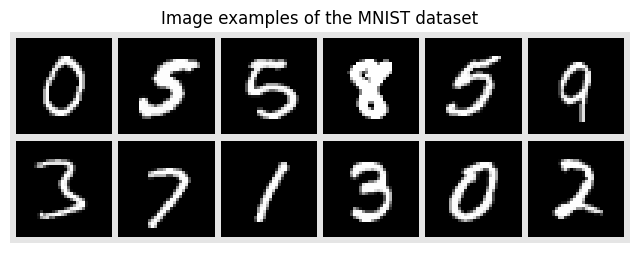

In [58]:
# Visualize some examples
NUM_IMAGES = 12
MNIST_images = torch.stack(
    [MNIST_train_dataset[np.random.randint(len(MNIST_train_dataset))][0] for idx in range(NUM_IMAGES)],
    dim=0,
)
img_grid = torchvision.utils.make_grid(MNIST_images, nrow=6, normalize=True, pad_value=0.9)
img_grid = img_grid.permute(1, 2, 0)

plt.figure(figsize=(8, 8))
plt.title("Image examples of the MNIST dataset")
plt.imshow(img_grid)
plt.axis("off")
plt.show()
plt.close()

Be careful ! Even if you put a transform when downloading the data and creating teh Pytorch Dataset, this is actually not applied until you load the data with a DataLoader.

For instance, when you load images in the range $[0,255]$ and you put the transform `ToTensor()`, this should automatically normalize the images in the range $[0,1]$ and transform them into Pytorch tensors. However, if you simply take the data from the DataSet *WITHOUT* the DataLoader...

In [59]:
# This does not apply the normalization to [0-1] (transform To.Tensor() )
MNIST_Xtrain_255 = MNIST_train_dataset.data.numpy()
MNIST_ytrain_255 = MNIST_train_dataset.targets.numpy()


In [60]:
print(MNIST_Xtrain_255.shape)
print(MNIST_ytrain_255.shape)

print(f"Min Pixel Value: {MNIST_Xtrain_255.min()} \nMax Pixel Value: {MNIST_Xtrain_255.max()}")
print(f"Mean Pixel Value {MNIST_Xtrain_255.mean()} \nPixel Values Std: {MNIST_Xtrain_255.std()}")
print(f"Min Pixel Value: {MNIST_Xtrain_255.min()} \nMax Pixel Value: {MNIST_Xtrain_255.max()}")

(60000, 28, 28)
(60000,)
Min Pixel Value: 0 
Max Pixel Value: 255
Mean Pixel Value 33.318421449829934 
Pixel Values Std: 78.56748998339798
Min Pixel Value: 0 
Max Pixel Value: 255


Instead, if we load them with the Dataloader...

In [61]:
MNIST_train_loader = DataLoader(MNIST_train_dataset, batch_size=len(MNIST_train_dataset))
MNIST_test_loader = DataLoader(MNIST_test_dataset, batch_size=len(MNIST_test_dataset))

MNIST_Xtrain_ima = np.squeeze(next(iter(MNIST_train_loader))[0].numpy())
MNIST_ytrain = next(iter(MNIST_train_loader))[1].numpy()

MNIST_Xtest_ima = np.squeeze(next(iter(MNIST_test_loader))[0].numpy())
MNIST_ytest = next(iter(MNIST_test_loader))[1].numpy()


In [62]:
print(MNIST_Xtrain_ima.shape)
print(MNIST_ytrain.shape)

print(MNIST_Xtest_ima.shape)
print(MNIST_ytest.shape)

print(f"Min Pixel Value: {MNIST_Xtrain_ima.min()} \nMax Pixel Value: {MNIST_Xtrain_ima.max()}")
print(f"Mean Pixel Value {MNIST_Xtrain_ima.mean()} \nPixel Values Std: {MNIST_Xtrain_ima.std()}")

print(f"Min Pixel Value: {MNIST_Xtest_ima.min()} \nMax Pixel Value: {MNIST_Xtest_ima.max()}")
print(f"Mean Pixel Value {MNIST_Xtest_ima.mean()} \nPixel Values Std: {MNIST_Xtest_ima.std()}")

(60000, 32, 32)
(60000,)
(10000, 32, 32)
(10000,)
Min Pixel Value: 0.0 
Max Pixel Value: 1.0
Mean Pixel Value 0.10003671795129776 
Pixel Values Std: 0.2752174437046051
Min Pixel Value: 0.0 
Max Pixel Value: 1.0
Mean Pixel Value 0.10145653039216995 
Pixel Values Std: 0.2774091958999634


(12, 32, 32)


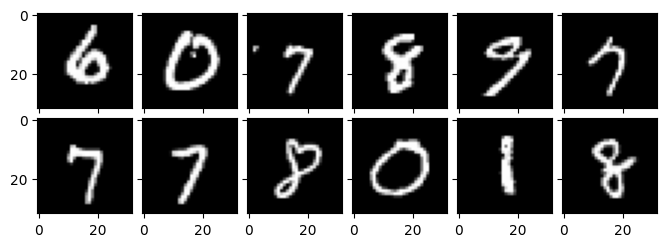

In [63]:
from mpl_toolkits.axes_grid1 import ImageGrid

NUM_IMAGES = 12
MNIST_grid = MNIST_Xtrain_ima[np.random.randint(0, len(MNIST_Xtrain_ima), 12), :, :]
print(MNIST_grid.shape)

fig = plt.figure(figsize=(8, 8))
grid = ImageGrid(
    fig,
    111,  # similar to subplot(111)
    nrows_ncols=(2, 6),  # creates 2x2 grid of axes
    axes_pad=0.1,  # pad between axes in inch.
)

for ax, im in zip(grid, MNIST_grid):
    # Iterating over the grid returns the Axes.
    ax.imshow(im, cmap="gray")

plt.show()

So we have 60k training images and 10K test images of size $[32 x 32]$. Let's load another dataset

### **SVHN dataset**

The Street View House Numbers (SVHN) dataset is a real-world image dataset for house number detection. It is similar to MNIST since it has the same digit classes (0 to 9), but it is significantly harder due to its real-world setting. SVHN is obtained from house numbers in Google Street View images.

It comprises RGB images of size $32x32$

We change them from RGB to grayscale to compare them with the MNIST images.


In [64]:
SVHN_train_dataset = SVHN(
    root=DATASET_PATH,
    split="train",
    download=True,
    transform=T.Compose([T.Grayscale(), T.ToTensor()]),
)
SVHN_test_dataset = SVHN(
    root=DATASET_PATH,
    split="test",
    download=True,
    transform=T.Compose([T.Grayscale(), T.ToTensor()]),
)

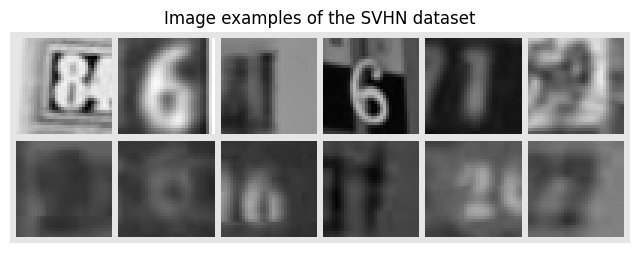

In [65]:
# Visualize some examples
NUM_IMAGES = 12
SVHN_images = torch.stack(
    [SVHN_test_dataset[np.random.randint(len(SVHN_test_dataset))][0] for idx in range(NUM_IMAGES)],
    dim=0,
)
img_grid = torchvision.utils.make_grid(SVHN_images, nrow=6, normalize=True, pad_value=0.9)
img_grid = img_grid.permute(1, 2, 0)

plt.figure(figsize=(8, 8))
plt.title("Image examples of the SVHN dataset")
plt.imshow(img_grid)
plt.axis("off")
plt.show()
plt.close()

In [66]:
SVHN_train_loader = DataLoader(SVHN_train_dataset, batch_size=len(SVHN_train_dataset))
SVHN_test_loader = DataLoader(SVHN_test_dataset, batch_size=len(SVHN_test_dataset))

SVHN_Xtrain_ima = np.squeeze(next(iter(SVHN_train_loader))[0].numpy())
SVHN_ytrain = next(iter(SVHN_train_loader))[1].numpy()

SVHN_Xtest_ima = np.squeeze(next(iter(SVHN_test_loader))[0].numpy())
SVHN_ytest = next(iter(SVHN_test_loader))[1].numpy()


In [67]:
print(SVHN_Xtrain_ima.shape)
print(SVHN_ytrain.shape)
print(SVHN_Xtest_ima.shape)
print(SVHN_ytest.shape)

print(f"Min Pixel Value: {SVHN_Xtrain_ima.min()} \nMax Pixel Value: {SVHN_Xtrain_ima.max()}")
print(f"Mean Pixel Value {SVHN_Xtrain_ima.mean()} \nPixel Values Std: {SVHN_Xtrain_ima.std()}")

print(f"Min Pixel Value: {SVHN_Xtest_ima.min()} \nMax Pixel Value: {SVHN_Xtest_ima.max()}")
print(f"Mean Pixel Value {SVHN_Xtest_ima.mean()} \nPixel Values Std: {SVHN_Xtest_ima.std()}")

(73257, 32, 32)
(73257,)
(26032, 32, 32)
(26032,)
Min Pixel Value: 0.0 
Max Pixel Value: 1.0


Mean Pixel Value 0.4452594220638275 
Pixel Values Std: 0.196975976228714
Min Pixel Value: 0.0 
Max Pixel Value: 1.0
Mean Pixel Value 0.45435550808906555 
Pixel Values Std: 0.2220025360584259


Here we have ~73K training images and ~26K test images of the same size $[32 x x32]$

### **USPS**

As last dataset, we will use the USPS dataset which contains images of digits (from 0 to 9) scanned from envelopes by the U.S. Postal Service. It contains a total of 9,298 $16x16$ pixel grayscale images. Images are centered, normalized and show a broad range of font styles.

Even in ths case, we pad them with 0 in order to have $32 x 32$ images.

In [68]:
USPS_train_dataset = USPS(
    root=DATASET_PATH,
    train=True,
    download=True,
    transform=T.Compose([T.Pad(8), T.ToTensor()]),
)
USPS_test_dataset = USPS(
    root=DATASET_PATH,
    train=False,
    download=True,
    transform=T.Compose([T.Pad(8), T.ToTensor()]),
)

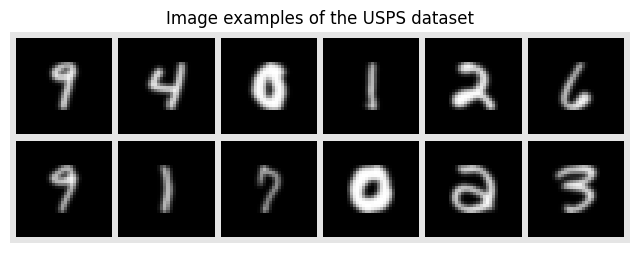

In [69]:
# Visualize some examples
NUM_IMAGES = 12
USPS_images = torch.stack(
    [USPS_train_dataset[np.random.randint(len(USPS_train_dataset))][0] for idx in range(NUM_IMAGES)],
    dim=0,
)
img_grid = torchvision.utils.make_grid(USPS_images, nrow=6, normalize=True, pad_value=0.9)
img_grid = img_grid.permute(1, 2, 0)

plt.figure(figsize=(8, 8))
plt.title("Image examples of the USPS dataset")
plt.imshow(img_grid)
plt.axis("off")
plt.show()
plt.close()

In [70]:
USPS_train_loader = DataLoader(USPS_train_dataset, batch_size=len(USPS_train_dataset))
USPS_test_loader = DataLoader(USPS_test_dataset, batch_size=len(USPS_test_dataset))

USPS_Xtrain_ima = np.squeeze(next(iter(USPS_train_loader))[0].numpy())
USPS_ytrain = next(iter(USPS_train_loader))[1].numpy()

USPS_Xtest_ima = np.squeeze(next(iter(USPS_test_loader))[0].numpy())
USPS_ytest = next(iter(USPS_test_loader))[1].numpy()

In [71]:
print(USPS_Xtrain_ima.shape)
print(USPS_ytrain.shape)
print(USPS_Xtest_ima.shape)
print(USPS_ytest.shape)

print(f"Min Pixel Value: {USPS_Xtrain_ima.min()} \nMax Pixel Value: {USPS_Xtrain_ima.max()}")
print(f"Mean Pixel Value {USPS_Xtrain_ima.mean()} \nPixel Values Std: {USPS_Xtrain_ima.std()}")

print(f"Min Pixel Value: {USPS_Xtest_ima.min()} \nMax Pixel Value: {USPS_Xtest_ima.max()}")
print(f"Mean Pixel Value {USPS_Xtest_ima.mean()} \nPixel Values Std: {USPS_Xtest_ima.std()}")

(7291, 32, 32)
(7291,)
(2007, 32, 32)
(2007,)
Min Pixel Value: 0.0 
Max Pixel Value: 0.9960784316062927
Mean Pixel Value 0.06171923503279686 
Pixel Values Std: 0.18373751640319824
Min Pixel Value: 0.0 
Max Pixel Value: 1.0
Mean Pixel Value 0.06497029960155487 
Pixel Values Std: 0.19083774089813232


We have ~7K training images and ~2k test images of size $[32 x 32]$

### **UMAP**

One of the first things to do, is to visually check the data to verify if it exists a domain gap and if the datasets are different.

Here, we will use the UMAP and t-SNE methods which are general manifold learning and non-linear dimension reduction algorithms (probably the two most-used ones). UMAP can be seen as a Riemannian extension of the t-SNE method (which uses an Euclidean distance).

[1] Leland McInnes, John Healy, James Melville. "UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction". 2018

[2] van der Maaten, L.J.P., Hinton, G.E. "Visualizing Data Using t-SNE". Journal of Machine Learning Research. 2008


Transform data so that instead than having 3D arrays of images we will have 2D arrays by vectorizing each image -> 32 x 32 = 1024

In [72]:
MNIST_Xtrain_ima.shape

(60000, 32, 32)

In [73]:
# MNIST
MNIST_Xtrain = np.reshape(MNIST_Xtrain_ima, (len(MNIST_Xtrain_ima), -1))
MNIST_Xtest = np.reshape(MNIST_Xtest_ima, (len(MNIST_Xtest_ima), -1))

print(MNIST_Xtrain.shape, MNIST_Xtest.shape)

# USPS
USPS_Xtrain = np.reshape(USPS_Xtrain_ima, (len(USPS_Xtrain_ima), -1))
USPS_Xtest = np.reshape(USPS_Xtest_ima, (len(USPS_Xtest_ima), -1))

print(USPS_Xtrain.shape, USPS_Xtest.shape)

# SVHN
SVHN_Xtrain = np.reshape(SVHN_Xtrain_ima, (len(SVHN_Xtrain_ima), -1))
SVHN_Xtest = np.reshape(SVHN_Xtest_ima, (len(SVHN_Xtest_ima), -1))

print(SVHN_Xtrain.shape, SVHN_Xtest.shape)

(60000, 1024) (10000, 1024)
(7291, 1024) (2007, 1024)
(73257, 1024) (26032, 1024)


Here, we randomly pick only 1000 samples per dataset for visualization and to reduce the computational burden.

In [74]:
# Reduced MNIST
ids = np.random.randint(0, len(MNIST_Xtrain), size=(1000))
MNIST_Xtrain_res = MNIST_Xtrain[ids, :]
MNIST_ytrain_res = MNIST_ytrain[ids]

# Reduced USPS
ids = np.random.randint(0, len(USPS_Xtrain), size=(1000))
USPS_Xtrain_res = USPS_Xtrain[ids]
USPS_ytrain_res = USPS_ytrain[ids]

# Reduced SVHN
ids = np.random.randint(0, len(SVHN_Xtrain), size=(1000))
SVHN_Xtrain_res = SVHN_Xtrain[ids]
SVHN_ytrain_res = SVHN_ytrain[ids]


# Reduced Data
xtot = np.concatenate((MNIST_Xtrain_res, USPS_Xtrain_res, SVHN_Xtrain_res), axis=0)  # all data
nMNIST = MNIST_Xtrain_res.shape[0]
nUSPS = USPS_Xtrain_res.shape[0]
nSVHN = SVHN_Xtrain_res.shape[0]


In [75]:
xp = UMAP().fit_transform(xtot)  # this should take ~50sec

print(xp.shape)

# separate again but now in 2D
xpMNIST = xp[:nMNIST, :]
xpUSPS = xp[nMNIST : nMNIST + nUSPS, :]
xpSVHN = xp[nMNIST + nUSPS :, :]

(3000, 2)


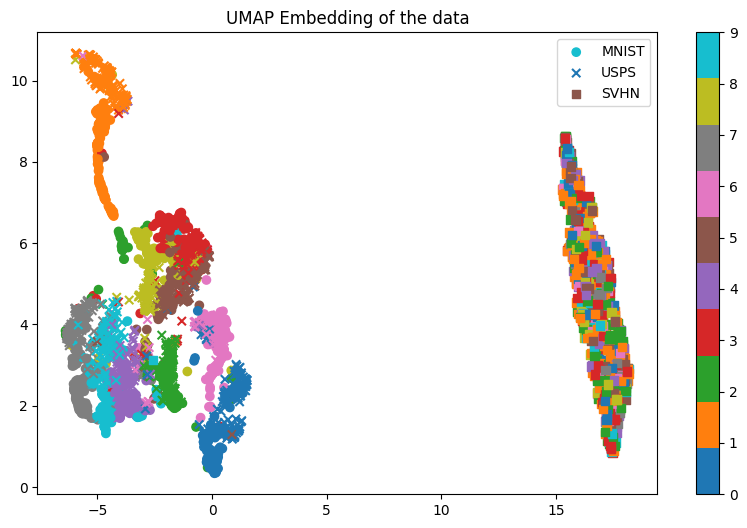

In [76]:
plt.figure(3, (10, 6))

plt.scatter(xpMNIST[:, 0], xpMNIST[:, 1], c=MNIST_ytrain_res, marker="o", cmap="tab10", label="MNIST")
plt.scatter(xpUSPS[:, 0], xpUSPS[:, 1], c=USPS_ytrain_res, marker="x", cmap="tab10", label="USPS")
plt.scatter(xpSVHN[:, 0], xpSVHN[:, 1], c=SVHN_ytrain_res, marker="s", cmap="tab10", label="SVHN")
plt.legend()
plt.colorbar()
plt.title("UMAP Embedding of the data")
plt.show()

In [77]:
xMNIST_USPS = np.concatenate((MNIST_Xtrain_res, USPS_Xtrain_res), axis=0)  # all data

xp = UMAP().fit_transform(xMNIST_USPS)  # this should take ~50sec

print(xp.shape)

# separate again but now in 2D
xpMNIST = xp[:nMNIST, :]
xpUSPS = xp[nMNIST : nMNIST + nUSPS, :]


(2000, 2)


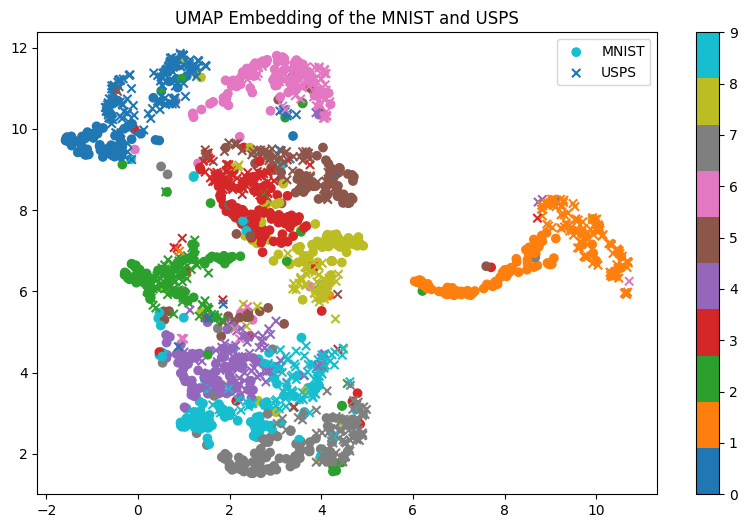

In [78]:
plt.figure(3, (10, 6))

plt.scatter(xpMNIST[:, 0], xpMNIST[:, 1], c=MNIST_ytrain_res, marker="o", cmap="tab10", label="MNIST")
plt.scatter(xpUSPS[:, 0], xpUSPS[:, 1], c=USPS_ytrain_res, marker="x", cmap="tab10", label="USPS")
plt.legend()
plt.colorbar()
plt.title("UMAP Embedding of the MNIST and USPS")
plt.show()

It seems that one dataset is quite different from the other two.

**Question**: What are your conclusions ? Re-run the code showing only the most similar datasets.

The SVHN dataset is quite different. While MNIST and UPS seem to have similar distributions, SVHN leaves in a complete different space of the 2D plane and the labels are not at all differentiated

**Question**: Can you see a domain shift between the datasets ?

Yes. 
SVHN differs in:
- Natural image statistics (color, lighting, background clutter)
- Digit crops coming from real-world scenes
- Different font/shape distribution


There is also some domain shift between the MNIST and UPSP datasets. There seems to be some label shift.

Now we can test the t-SNE algorithm to check whether your conclusions are confirmed.

In [ ]:
%time 
from sklearn.manifold import TSNE

xp = TSNE().fit_transform(xtot)  # this should take around 50 sec

print(xp.shape)

# separate again but now in 2D
xpMNIST = xp[:nMNIST, :]
xpUSPS = xp[nMNIST : nMNIST + nUSPS, :]
xpSVHN = xp[nMNIST + nUSPS :, :]
print(xpMNIST.shape, xpUSPS.shape, xpSVHN.shape)

CPU times: user 6 µs, sys: 0 ns, total: 6 µs
Wall time: 13.1 µs


(3000, 2)
(1000, 2) (1000, 2) (1000, 2)


Text(0.5, 1.0, 'TSNE Embedding of the data')

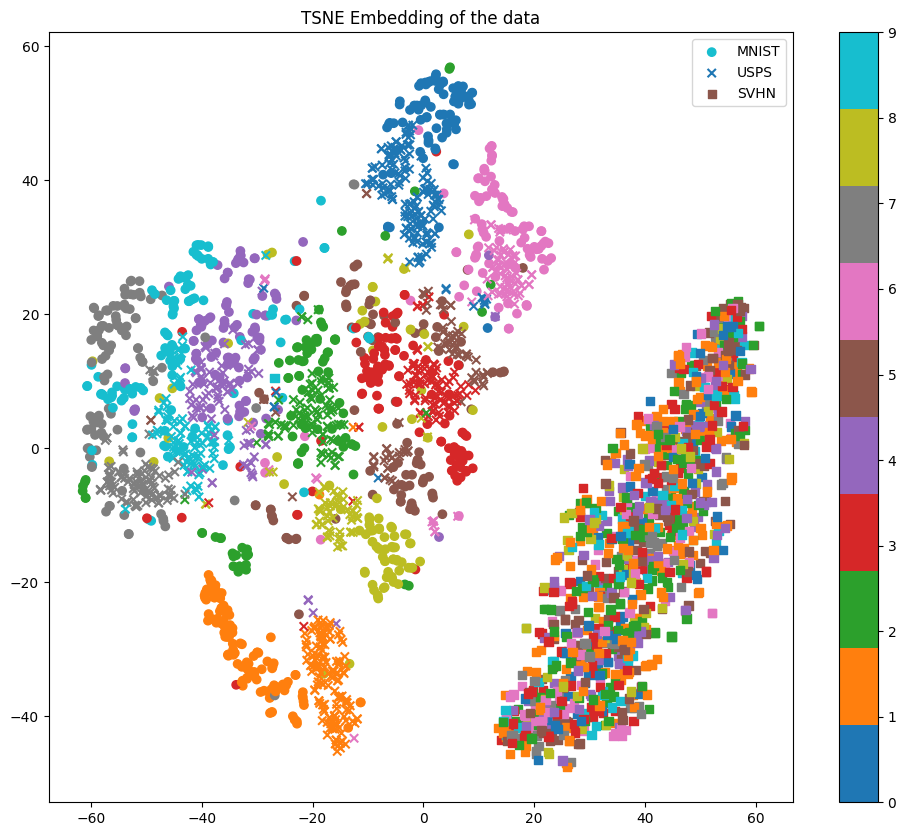

In [80]:
plt.figure(3, (12, 10))

plt.scatter(xpMNIST[:, 0], xpMNIST[:, 1], c=MNIST_ytrain_res, marker="o", cmap="tab10", label="MNIST")
plt.scatter(xpUSPS[:, 0], xpUSPS[:, 1], c=USPS_ytrain_res, marker="x", cmap="tab10", label="USPS")
plt.scatter(xpSVHN[:, 0], xpSVHN[:, 1], c=SVHN_ytrain_res, marker="s", cmap="tab10", label="SVHN")
plt.legend()
plt.colorbar()
plt.title("TSNE Embedding of the data")

**Question**: can you confirm your previous conclusions ?

tSNE confirms the findings of UMAP.

It seems that one dataset is quite different from the other two data-sets.

**Question**: Analyse that dataset alone using UMAP (faster)

In [81]:
xsvhnh = UMAP().fit_transform(SVHN_Xtrain_res)

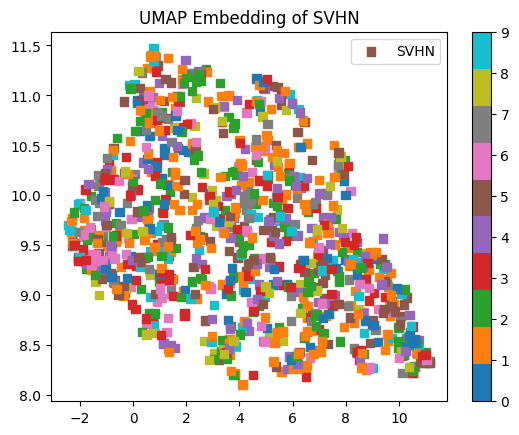

In [82]:
plt.scatter(xsvhnh[:, 0], xsvhnh[:, 1], c=SVHN_ytrain_res, marker="s", cmap="tab10", label="SVHN")
plt.legend()
plt.colorbar()
plt.title("UMAP Embedding of SVHN")
plt.show()

**Question**: Are the data clearly clustered and well separated as for the other two datasets ? If not, why is that in your opinion ?

Hint: think about the input space of UMAP...

The embedding forms one main connected cloud.

- Digit colors (0–9) are heavily mixed, with no clean class-wise clusters.
- Any local structure that exists is weak and not aligned with digit identity.

So UMAP is not discovering digit-separated manifolds here
This is expected given the high intra-class variability and poor class alignment in pixel space.

# Unsupervised Domain Adaptation

The three data-sets have the same features $\mathcal{X}$ (all images have size $[32 x 32]$)
 and the same classes (output labels) $\mathcal{Y}$ but they have different marginal $p(X)$ distributions.

In this part, we will assume that we only have labeled data in the source domain $S$ but not int the target domain $T$. By matching the source $p_S(X)$ and target $p_T(X)$ marginal distributions, one can hope that a classifier learnt on $S$ will also work on $T$.

Here, you will implement and test the following algorithm based on subspace alignement:

B. Fernando et al. "*Unsupervised Visual Domain Adaptation Using Subspace Alignment*". ICCV, 2013.

The first thing to do is to choose the source domain and the target domain.
Let's start with the MNIST dataset as source and USPS as target.

We will use the previousyly computed reduced datasets to speed up computations.

In [83]:
# Source domain
XtrainS = MNIST_Xtrain_res
ytrainS = MNIST_ytrain_res
XtestS = MNIST_Xtest
ytestS = MNIST_ytest

# # Target domain
XtrainT = USPS_Xtrain_res
ytrainT = USPS_ytrain_res
XtestT = USPS_Xtest
ytestT = USPS_ytest

# Target domain
# XtrainT = SVHN_Xtrain_res
# ytrainT = SVHN_ytrain_res
# XtestT = SVHN_Xtest
# ytestT = SVHN_ytest

Ns = 1000  # number of samples in source domain
Nt = 1000  # number of samples in target domain

Implement the method following the description of the method in the slides of the lecture (around slide 75).  

In [84]:
from sklearn.decomposition import PCA


def SA(XTrainS, XTestS, XTrainT, XTestT, d=10):
    """Subspace Alignment (SA)

    Input
    XTrainS : Input training source data [NTrS,D]
    XTestS : Input test source data [NTeS,D]
    XTrainT : Input training target data [NTrT,D]
    XTestT : Input test target data [NTeT,D]
    d : number of PCA components

    Output
    XTrainSp : projected and transformed source training data [NTrS,d]
    XTestSp : projected and transformed source test data [NTeS,d]
    XTrainTp : projected training target data [NTrT,d]
    XTestTp : projected test target data [NTeT,d]
    """
    # 1. PCA on source domain
    pca_s = PCA(n_components=d)
    pca_s.fit(XTrainS)
    Ps = pca_s.components_.T  # shape: [D, d]

    # 2. PCA on target domain
    pca_t = PCA(n_components=d)
    pca_t.fit(XTrainT)
    Pt = pca_t.components_.T  # shape: [D, d]

    # 3. Alignment matrix
    M = Ps.T @ Pt  # shape: [d, d]

    # 4. Project and align source data
    XTrainSp = XTrainS @ Ps @ M
    XTestSp = XTestS @ Ps @ M

    # 5. Project target data
    XTrainTp = XTrainT @ Pt
    XTestTp = XTestT @ Pt

    return XTrainSp, XTestSp, XTrainTp, XTestTp


We start by veryfying the score of a classifier trained on the source domain and tested on the target domain (no adaptation).

You can use the classifier you want (e.g., logistic regression, SVM, ...)

In [85]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


def baseline_train_source_test_both(
    XtrainS,
    ytrainS,
    XtestS,
    ytestS,
    XtestT,
    ytestT,
):
    clf = LogisticRegression(
        max_iter=1000,
        solver="lbfgs",
        multi_class="auto",
    )
    clf.fit(XtrainS, ytrainS)

    acc_source = accuracy_score(ytestS, clf.predict(XtestS))
    acc_target = accuracy_score(ytestT, clf.predict(XtestT))

    return acc_source, acc_target


In [86]:
acc_S_usps, acc_T_usps = baseline_train_source_test_both(
    MNIST_Xtrain_res,
    MNIST_ytrain_res,
    MNIST_Xtest,
    MNIST_ytest,
    USPS_Xtest,
    USPS_ytest,
)

acc_S_svhn, acc_T_svhn = baseline_train_source_test_both(
    MNIST_Xtrain_res,
    MNIST_ytrain_res,
    MNIST_Xtest,
    MNIST_ytest,
    SVHN_Xtest,
    SVHN_ytest,
)

print("Train on MNIST")
print("Test set   | Accuracy")
print(f"MNIST      | {acc_S_usps:.3f}")
print(f"USPS       | {acc_T_usps:.3f}")
print(f"SVHN       | {acc_T_svhn:.3f}")


/home/fotis/MVA/RepLear/.venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


/home/fotis/MVA/RepLear/.venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Train on MNIST
Test set   | Accuracy
MNIST      | 0.862
USPS       | 0.571
SVHN       | 0.130


We first evaluate a baseline classifier trained on the source domain and tested on different target domains without any form of adaptation. A logistic regression trained on MNIST achieves high accuracy when evaluated on MNIST itself, but its performance drops significantly when tested on USPS, despite the visual similarity between the two datasets. The degradation is even more severe when testing on SVHN. This gap between in-domain and cross-domain performance clearly highlights the presence of a domain shift

To reduce dimensionality, we can also first compute PCA using the source training set and then project (i.e., transform) all data (source and target, training and test) on the first $d$ components.

**Question**: try different values of $d$. Is there a difference with the previous full-training data appraoch ?

In [87]:
import warnings

warnings.filterwarnings("ignore")


In [88]:
def pca_source_train_test_both(
    XtrainS,
    ytrainS,
    XtestS,
    ytestS,
    XtestT,
    ytestT,
    d,
):
    # PCA fitted on SOURCE TRAINING SET ONLY
    pca = PCA(n_components=d)
    pca.fit(XtrainS)

    # Project data
    XtrainS_p = pca.transform(XtrainS)
    XtestS_p = pca.transform(XtestS)
    XtestT_p = pca.transform(XtestT)

    # Train classifier on projected source
    clf = LogisticRegression(
        max_iter=1000,
        solver="lbfgs",
        multi_class="auto",
    )
    clf.fit(XtrainS_p, ytrainS)

    acc_S = accuracy_score(ytestS, clf.predict(XtestS_p))
    acc_T = accuracy_score(ytestT, clf.predict(XtestT_p))

    return acc_S, acc_T


ds = [5, 10, 20, 50, 100, 200]

print("d   | MNIST test | USPS test")
for d in ds:
    acc_S, acc_T = pca_source_train_test_both(
        MNIST_Xtrain_res,
        MNIST_ytrain_res,
        MNIST_Xtest,
        MNIST_ytest,
        USPS_Xtest,
        USPS_ytest,
        d,
    )
    print(f"{d:3d} | {acc_S:.3f}      | {acc_T:.3f}")


d   | MNIST test | USPS test


  5 | 0.671      | 0.415
 10 | 0.795      | 0.553
 20 | 0.846      | 0.623
 50 | 0.860      | 0.604
100 | 0.862      | 0.585
200 | 0.860      | 0.572


In [89]:
print("d   | MNIST test | SVHN test")
for d in [5, 10, 20, 50, 100, 200]:
    acc_S, acc_T = pca_source_train_test_both(
        MNIST_Xtrain_res,
        MNIST_ytrain_res,
        MNIST_Xtest,
        MNIST_ytest,
        SVHN_Xtest,
        SVHN_ytest,
        d,
    )
    print(f"{d:3d} | {acc_S:.3f}      | {acc_T:.3f}")


d   | MNIST test | SVHN test
  5 | 0.671      | 0.089
 10 | 0.795      | 0.100
 20 | 0.845      | 0.112
 50 | 0.860      | 0.123
100 | 0.859      | 0.120
200 | 0.861      | 0.119




For **MNIST -> USPS**, varying the number of PCA components shows that increasing d  quickly restores in-domain performance on MNIST, while the accuracy on USPS slightly improves for intermediate values of  d and then saturates. The best cross-domain performance remains comparable to the no-PCA baseline, indicating that PCA fitted on the source does not significantly reduce the domain gap, but also does not severely degrade transfer once enough components are retained.

For **MNIST -> SVHN**, the behavior is markedly different. While MNIST accuracy again increases with  d and reaches the baseline level, the accuracy on SVHN remains very low for all values of  d, close to random guessing. Increasing the dimensionality does not lead to meaningful improvements, confirming that PCA on the source domain is ineffective under a strong domain shift.

Overall, these results show that source-only dimensionality reduction preserves in-domain performance but does not address cross-domain discrepancies.


We can now test the SA approach.

**Question**: try different values of $d$. Does the performance improve on the target domain ? Try at least two different ML methods (one linear and one non-linear) and one DL architecture (it can be a pre-trained model or a simple architecture). What's the best ?

In [90]:
def evaluate_with_sa(
    XtrainS,
    ytrainS,
    XtestS,
    ytestS,
    XtrainT,
    ytrainT,
    XtestT,
    ytestT,
    d,
    clf,
):
    XTrainSp, XTestSp, XTrainTp, XTestTp = SA(
        XtrainS,
        XtestS,
        XtrainT,
        XtestT,
        d=d,
    )

    clf.fit(XTrainSp, ytrainS)

    acc_S = accuracy_score(ytestS, clf.predict(XTestSp))
    acc_T = accuracy_score(ytestT, clf.predict(XTestTp))

    return acc_S, acc_T


import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


def train_and_eval_mlp(
    XtrainS,
    ytrainS,
    XtestS,
    ytestS,
    XtestT,
    ytestT,
    d,
    epochs=10,
    lr=1e-3,
    batch_size=128,
):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = MLP(d).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    XtrainS_t = torch.tensor(XtrainS, dtype=torch.float32)
    ytrainS_t = torch.tensor(ytrainS, dtype=torch.long)
    XtestS_t = torch.tensor(XtestS, dtype=torch.float32)
    ytestS_t = torch.tensor(ytestS, dtype=torch.long)
    XtestT_t = torch.tensor(XtestT, dtype=torch.float32)
    ytestT_t = torch.tensor(ytestT, dtype=torch.long)

    train_loader = DataLoader(
        TensorDataset(XtrainS_t, ytrainS_t),
        batch_size=batch_size,
        shuffle=True,
    )

    # Train
    model.train()
    for _ in range(epochs):
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

    # Evaluate
    model.eval()
    with torch.no_grad():
        acc_S = (model(XtestS_t.to(device)).argmax(1).cpu() == ytestS_t).float().mean().item()
        acc_T = (model(XtestT_t.to(device)).argmax(1).cpu() == ytestT_t).float().mean().item()

    return acc_S, acc_T


In [91]:
import torch
from sklearn.svm import SVC, LinearSVC

ds = [5, 10, 20, 50, 100]


lin_clf = LinearSVC()
rbf_clf = SVC(kernel="rbf", gamma="scale")


class MLP(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


In [92]:
import pandas as pd


def sweep_sa_sklearn(name, clf, ds):
    rows = []
    for d in ds:
        acc_S, acc_T = evaluate_with_sa(
            XtrainS,
            ytrainS,
            XtestS,
            ytestS,
            XtrainT,
            ytrainT,
            XtestT,
            ytestT,
            d=d,
            clf=clf,
        )
        rows.append({"model": name, "d": d, "acc_source": acc_S, "acc_target": acc_T})
    return rows


def sweep_sa_dl(ds):
    rows = []
    for d in ds:
        XTrainSp, XTestSp, XTrainTp, XTestTp = SA(XtrainS, XtestS, XtrainT, XtestT, d=d)

        acc_S, acc_T = train_and_eval_mlp(XTrainSp, ytrainS, XTestSp, ytestS, XTestTp, ytestT, d=d)

        rows.append({"model": "DL", "d": d, "acc_source": acc_S, "acc_target": acc_T})
    return rows


In [93]:
rows = []

# ===== MNIST -> USPS =====
XtrainT, ytrainT = USPS_Xtrain_res, USPS_ytrain_res
XtestT, ytestT = USPS_Xtest, USPS_ytest

rows += [{**r, "target": "USPS"} for r in sweep_sa_sklearn("Linear", lin_clf, ds)]
rows += [{**r, "target": "USPS"} for r in sweep_sa_sklearn("NonLinear", rbf_clf, ds)]

# ===== MNIST -> SVHN =====
XtrainT, ytrainT = SVHN_Xtrain_res, SVHN_ytrain_res
XtestT, ytestT = SVHN_Xtest, SVHN_ytest

rows += [{**r, "target": "SVHN"} for r in sweep_sa_sklearn("Linear", lin_clf, ds)]
rows += [{**r, "target": "SVHN"} for r in sweep_sa_sklearn("NonLinear", rbf_clf, ds)]

df_sa = pd.DataFrame(rows)
print(df_sa)


        model    d  acc_source  acc_target target
0      Linear    5      0.6313    0.309417   USPS
1      Linear   10      0.7768    0.461385   USPS
2      Linear   20      0.8423    0.471350   USPS
3      Linear   50      0.8501    0.579970   USPS
4      Linear  100      0.8400    0.645740   USPS
5   NonLinear    5      0.6793    0.389138   USPS
6   NonLinear   10      0.8342    0.603388   USPS
7   NonLinear   20      0.8851    0.653214   USPS
8   NonLinear   50      0.9009    0.667663   USPS
9   NonLinear  100      0.9012    0.670154   USPS
10     Linear    5      0.5268    0.066994   SVHN
11     Linear   10      0.6867    0.110326   SVHN
12     Linear   20      0.8071    0.096766   SVHN
13     Linear   50      0.8528    0.073909   SVHN
14     Linear  100      0.8599    0.072565   SVHN
15  NonLinear    5      0.4191    0.086778   SVHN
16  NonLinear   10      0.5603    0.081016   SVHN
17  NonLinear   20      0.7899    0.176053   SVHN
18  NonLinear   50      0.8980    0.096074   SVHN


In [94]:
# ===== MNIST -> USPS (DL) =====
XtrainT, ytrainT = USPS_Xtrain_res, USPS_ytrain_res
XtestT, ytestT = USPS_Xtest, USPS_ytest

rows += [{**r, "target": "USPS"} for r in sweep_sa_dl(ds)]

# ===== MNIST -> SVHN (DL) =====
XtrainT, ytrainT = SVHN_Xtrain_res, SVHN_ytrain_res
XtestT, ytestT = SVHN_Xtest, SVHN_ytest

rows += [{**r, "target": "SVHN"} for r in sweep_sa_dl(ds)]

df_sa = pd.DataFrame(rows)
print(df_sa)


        model    d  acc_source  acc_target target
0      Linear    5      0.6313    0.309417   USPS
1      Linear   10      0.7768    0.461385   USPS
2      Linear   20      0.8423    0.471350   USPS
3      Linear   50      0.8501    0.579970   USPS
4      Linear  100      0.8400    0.645740   USPS
5   NonLinear    5      0.6793    0.389138   USPS
6   NonLinear   10      0.8342    0.603388   USPS
7   NonLinear   20      0.8851    0.653214   USPS
8   NonLinear   50      0.9009    0.667663   USPS
9   NonLinear  100      0.9012    0.670154   USPS
10     Linear    5      0.5268    0.066994   SVHN
11     Linear   10      0.6867    0.110326   SVHN
12     Linear   20      0.8071    0.096766   SVHN
13     Linear   50      0.8528    0.073909   SVHN
14     Linear  100      0.8599    0.072565   SVHN
15  NonLinear    5      0.4191    0.086778   SVHN
16  NonLinear   10      0.5603    0.081016   SVHN
17  NonLinear   20      0.7899    0.176053   SVHN
18  NonLinear   50      0.8980    0.096074   SVHN


For the **MNIST -> USPS** transfer, Subspace Alignment leads to a clear and consistent improvement in target-domain performance compared to all previous baselines. For the linear model, the target accuracy increases from very low values at small ( d ) to a maximum of about 0.61 at ( d = 100 ), showing that aligning the source and target subspaces already helps a simple classifier generalize across domains. The non-linear model benefits even more from SA: target accuracy steadily increases with ( d ), peaking around 0.69 for ( d = 50 ), which is the best result obtained overall. This indicates that once the domains are aligned, a non-linear decision boundary can exploit the shared structure more effectively than a linear one. The deep learning model also improves over the no-adaptation and PCA-only baselines, but its performance remains below that of the non-linear classical model, suggesting that the simple MLP used here does not fully leverage the aligned representation.

For the **MNIST -> SVHN** transfer, the situation is very different. Across all models and values of ( d ), target accuracy remains very low, never exceeding approximately 0.18. Although source-domain accuracy increases with ( d ), this does not translate into improved performance on the target domain. Neither increasing the subspace dimensionality nor using more expressive classifiers leads to stable gains. This shows that the discrepancy between MNIST and SVHN is too large to be compensated by a linear subspace alignment, and that the main limitation lies in the representation itself rather than in the classifier capacity.

Overall, these results demonstrate that Subspace Alignment is effective for **moderate domain shifts**, such as MNIST to USPS, where the two domains share similar underlying structure. In this case, SA significantly reduces the domain gap and allows non-linear classifiers to achieve strong cross-domain performance. In contrast, for **strong domain shifts** like MNIST to SVHN, SA fails to provide meaningful improvements.


**Question**: Use the UMAP or t-SNE visualization to check whether the data are more similar after the SA adaptation. What can you conclude ?

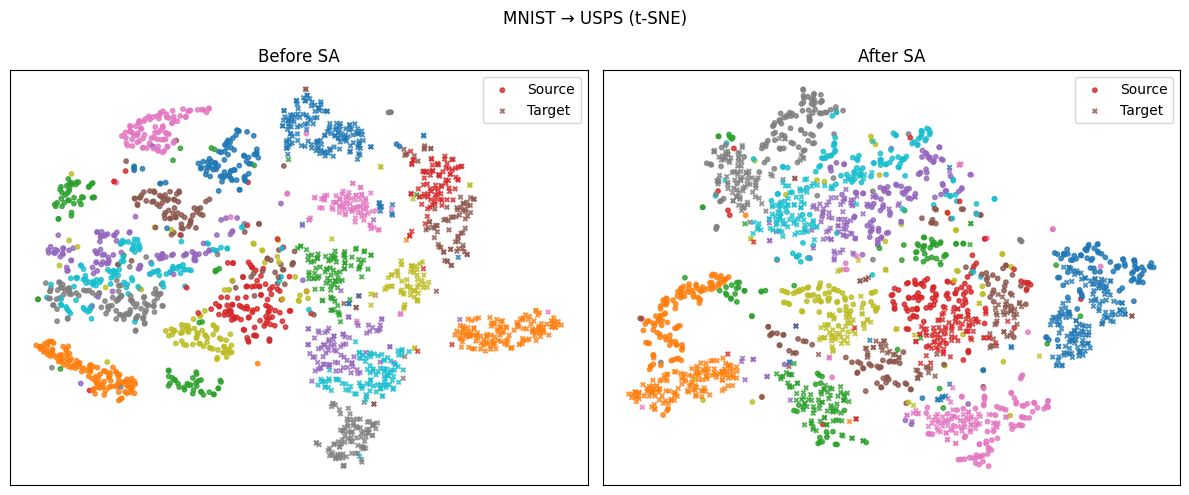

In [ ]:
d = 50
n_samples = 1000
perplexity = 30
rng = np.random.RandomState(0)

idxS = rng.choice(MNIST_Xtrain_res.shape[0], n_samples, replace=False)
idxT = rng.choice(USPS_Xtrain_res.shape[0], n_samples, replace=False)

XS = MNIST_Xtrain_res[idxS]
XT = USPS_Xtrain_res[idxT]
yS = MNIST_ytrain_res[idxS]
yT = USPS_ytrain_res[idxT]

pca_s = PCA(d).fit(XS)
pca_t = PCA(d).fit(XT)

Ps = pca_s.components_.T
Pt = pca_t.components_.T

ZS_before = XS @ Ps
ZT_before = XT @ Pt

Z_before = np.vstack([ZS_before, ZT_before])

M = Ps.T @ Pt
ZS_after = XS @ Ps @ M
ZT_after = XT @ Pt

Z_after = np.vstack([ZS_after, ZT_after])

tsne = TSNE(n_components=2, perplexity=perplexity, init="pca", learning_rate="auto", random_state=0)

emb_before = tsne.fit_transform(Z_before)
emb_after = tsne.fit_transform(Z_after)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, emb, title in zip(axes, [emb_before, emb_after], ["Before SA", "After SA"]):
    ax.scatter(emb[:n_samples, 0], emb[:n_samples, 1], c=yS, cmap="tab10", s=10, alpha=0.8, label="Source")
    ax.scatter(
        emb[n_samples:, 0],
        emb[n_samples:, 1],
        c=yT,
        cmap="tab10",
        s=10,
        alpha=0.8,
        marker="x",
        label="Target",
    )
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend()

plt.suptitle("MNIST → USPS (t-SNE)")
plt.tight_layout()


We can clearly see that SA adaptation reduced the domain shift, pulling the same labels closers in the tSNE space

**Question**: Repeat the same experiments for different Source and Target domains. Use at least the two followng configurations:

Source: MNIST, Target: USPS

Source MNIST, Target: SVHN

**Queston**: Comment the results

Done in one pass

**Question**: What does it happen if you decrease the number of samples for the labeled training set? Is it expected based on the theory seen during the lecture ?

When the number of labeled samples in the source training set is reduced, performance degrades on both the source and the target domains, with a much stronger impact on the target domain. This effect is particularly pronounced after applying Subspace Alignment.

This behavior is fully expected from the theory seen during the lecture. Unsupervised domain adaptation rely on two key assumptions: (i) the source classifier is well learned, and (ii) the source and target distributions can be aligned in a shared representation space. When the labeled source dataset is small, the empirical risk minimization on the source becomes unreliable, and the learned hypothesis no longer approximates the optimal source classifier. According to domain adaptation bounds, this increases the source error term and indirectly worsens the target error bound, even if the divergence between domains is reduced.